# v3.2 — Uji stres takikardia & analisis sensitivitas

Versi minor, **evaluasi saja**: tidak ada training, paket produksi tidak disentuh. Menindaklanjuti review eksternal yang
menemukan bahwa paket v3.1 menebak ritme cepat yang teratur sebagai AFIB/AFL. Protokol v3 tidak menangkapnya karena data uji
AFDB hampir tidak punya ritme normal yang cepat.

| # | Analisis | Model |
|---|---|---|
| 1 | Ritme teratur sintetis 60–170 bpm × 4 jenis variasi detak | yang punya bobot: v1 (`final.joblib`), v2, v3.1 |
| 2 | Window Normal/AFL **asli** per pita detak jantung | semua model yang OOF-nya ada (v1–v6) |
| 3 | Sensitivitas tanpa pasien 04936 (58% window AFL; labelnya dipertanyakan reviewer) | v1, v2, v3.1 |
| 4 | Bootstrap bersarang: bias dipilih ulang di setiap sampel bootstrap | v3.1 vs v2, v1 |
| 5 | Simulasi aturan produk "detak cepat & teratur → takikardia teratur, perlu dicek" | v3.1 |

Catatan: model v4–v6 tidak menyimpan bobot, jadi hanya bisa diuji di window AFDB (analisis 2), tidak di data sintetis.
Prasyarat: OOF v3–v6 di `../cache/oof_robust/`. Logika ada di `takikardia.py`. Bagian lambat (±10 menit) di-cache di `../cache/v3_2/`.

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import takikardia as T
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)

t0 = time.perf_counter()
res = T.run_all()
print(f"selesai {time.perf_counter() - t0:.0f}s")
L = res["labels"]

/home/farhanlhsn/projects/sihedaf-v2/.venv/lib/python3.13/site-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


selesai 586s


## 1. Ritme teratur sintetis

Setiap titik: 50 window 10 detik dengan detak tetap ditambah variasi kecil. Ritme seperti ini secara klinis **normal**
(sinus takikardia saat aktivitas), kecuali AFL 2:1 yang dari interval RR saja memang hampir tidak bisa dibedakan.

=== v1 (sebelum revisi), argmax — ambang (< 50% Normal): {'tanpa variasi': 115, 'seragam ±10 ms': 110, 'Gauss sd 10 ms': 110, 'Gauss sd 20 ms': 110}


,tanpa variasi,seragam ±10 ms,Gauss sd 10 ms,Gauss sd 20 ms
90 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL
95 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL
100 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,98% N / 2% AFIB / 0% AFL
105 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,82% N / 18% AFIB / 0% AFL
110 bpm,100% N / 0% AFIB / 0% AFL,24% N / 0% AFIB / 76% AFL,18% N / 0% AFIB / 82% AFL,8% N / 14% AFIB / 78% AFL
115 bpm,0% N / 0% AFIB / 100% AFL,0% N / 0% AFIB / 100% AFL,0% N / 0% AFIB / 100% AFL,0% N / 6% AFIB / 94% AFL


=== v2 produksi, bias [0; 2; −3] — ambang (< 50% Normal): {'tanpa variasi': 115, 'seragam ±10 ms': 115, 'Gauss sd 10 ms': 115, 'Gauss sd 20 ms': 110}


,tanpa variasi,seragam ±10 ms,Gauss sd 10 ms,Gauss sd 20 ms
90 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,96% N / 4% AFIB / 0% AFL
95 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,90% N / 10% AFIB / 0% AFL
100 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,88% N / 12% AFIB / 0% AFL
105 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,54% N / 46% AFIB / 0% AFL
110 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,88% N / 12% AFIB / 0% AFL,8% N / 92% AFIB / 0% AFL
115 bpm,0% N / 0% AFIB / 100% AFL,0% N / 0% AFIB / 100% AFL,0% N / 72% AFIB / 28% AFL,0% N / 100% AFIB / 0% AFL


=== v3.1 produksi (referensi) — ambang (< 50% Normal): {'tanpa variasi': 115, 'seragam ±10 ms': 115, 'Gauss sd 10 ms': 115, 'Gauss sd 20 ms': 115}


,tanpa variasi,seragam ±10 ms,Gauss sd 10 ms,Gauss sd 20 ms
90 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL
95 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL
100 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL
105 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,94% N / 6% AFIB / 0% AFL
110 bpm,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,100% N / 0% AFIB / 0% AFL,76% N / 24% AFIB / 0% AFL
115 bpm,0% N / 0% AFIB / 100% AFL,0% N / 0% AFIB / 100% AFL,6% N / 32% AFIB / 62% AFL,4% N / 96% AFIB / 0% AFL


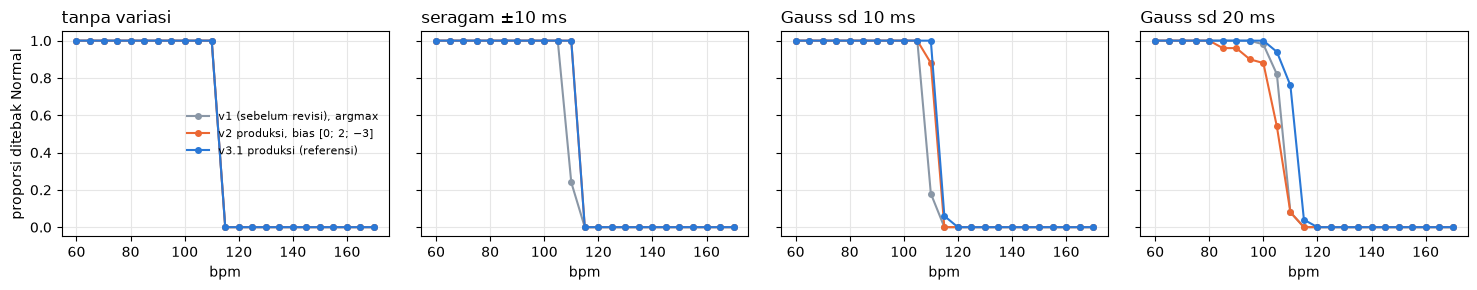

In [2]:
for m, tabs in res["stress"].items():
    df = pd.DataFrame({j: [f"{t[0]:.0%} N / {t[1]:.0%} AFIB / {t[2]:.0%} AFL" for t in tab] for j, tab in tabs.items()},
                      index=[f"{b} bpm" for b in res["bpms"]])
    print(f"=== {L[m]} — ambang (< 50% Normal): {res['threshold'][m]}")
    display(df.iloc[6:12])

fig, axes = plt.subplots(1, len(res["jitters"]), figsize=(15, 3), sharey=True)
for ax, j in zip(axes, res["jitters"]):
    for m, col in (("v1", "#8A97A6"), ("v2_prod", "#eb6834"), ("v31", "#2a78d6")):
        ax.plot(res["bpms"], [t[0] for t in res["stress"][m][j]], "o-", color=col, ms=4, label=L[m])
    ax.set_title(j, loc="left"); ax.set_xlabel("bpm"); ax.grid(color="0.9")
axes[0].set_ylabel("proporsi ditebak Normal"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Window asli per pita detak jantung

Angka = proporsi tebakan Normal / AFIB / AFL (rata-rata 5 ulangan, OOF). Baris Normal ≥ 110 bpm adalah alarm palsu takikardia
yang ada di AFDB, meski jumlahnya sedikit.

In [3]:
rows = []
for key, v in res["by_hr"].items():
    rows.append({"kelas | pita": key, "window": v["n"], "pasien": v["n_pasien"],
                 **{L[m]: f"{v[m][0]:.0%} / {v[m][1]:.0%} / {v[m][2]:.0%}" for m in L}})
display(pd.DataFrame(rows).set_index("kelas | pita"))
print("Keteraturan (koefisien variasi IBI):", {k: round(v["median"], 3) for k, v in res["cv_desc"].items()})

,window,pasien,"v1 (sebelum revisi), argmax","v2 produksi, bias [0; 2; −3]",v3.1 produksi (referensi),v4 ensemble MT + BiGRU,v5 bobot lunak,v6 late fusion RR + EKG
kelas | pita,,,,,,,,
Normal | 0–100 bpm,89566,21,91% / 8% / 0%,86% / 14% / 0%,93% / 7% / 0%,94% / 6% / 0%,94% / 6% / 0%,97% / 3% / 0%
Normal | 100–110 bpm,8766,12,86% / 13% / 1%,82% / 18% / 0%,87% / 13% / 0%,88% / 12% / 0%,88% / 12% / 0%,93% / 7% / 0%
Normal | 110–120 bpm,568,10,34% / 49% / 18%,22% / 71% / 6%,41% / 51% / 8%,41% / 51% / 8%,41% / 50% / 9%,50% / 48% / 2%
Normal | 120–∞ bpm,100,7,6% / 70% / 25%,0% / 98% / 2%,5% / 90% / 5%,6% / 87% / 7%,5% / 89% / 6%,14% / 79% / 7%
AFIB | 0–100 bpm,46038,23,6% / 93% / 1%,2% / 98% / 0%,8% / 92% / 0%,7% / 93% / 0%,8% / 92% / 0%,11% / 89% / 0%
AFIB | 100–110 bpm,10716,19,1% / 97% / 2%,1% / 99% / 0%,4% / 96% / 0%,3% / 97% / 0%,3% / 96% / 0%,3% / 97% / 0%
AFIB | 110–120 bpm,5045,20,1% / 96% / 4%,0% / 99% / 0%,1% / 99% / 1%,1% / 99% / 1%,1% / 99% / 1%,1% / 99% / 0%
AFIB | 120–∞ bpm,4027,17,0% / 75% / 25%,0% / 96% / 4%,0% / 95% / 4%,0% / 95% / 4%,0% / 95% / 5%,1% / 97% / 2%
AFL | 0–100 bpm,156,4,81% / 15% / 4%,78% / 22% / 0%,82% / 18% / 0%,81% / 19% / 0%,81% / 19% / 0%,80% / 20% / 0%


Keteraturan (koefisien variasi IBI): {'Normal': 0.025, 'AFIB': 0.213, 'AFL': 0.03, 'Normal ≥120 bpm': 0.182, 'AFL ≥120 bpm': 0.033}


## 3. Sensitivitas tanpa pasien 04936

04936 menyumbang sebagian besar window AFL. Window pasien itu dikeluarkan dari evaluasi (bias cross-fit dihitung ulang tanpa dia).
Model **tidak** dilatih ulang, jadi 04936 tetap ada di data latih fold lain (batasan).

In [4]:
print(f"Porsi window AFL dari {res['suspect']}: {res['afl_share_suspect']:.0%}")
sens = []
for lab, s in (("semua pasien", res["sens_all"]), (f"tanpa {res['suspect']}", res["sens_wo"])):
    for k, r in s["rows"].items():
        sens.append({"data": lab, "model": L[k], **{m: f"{v[0]:.3f} [{v[1]:.2f}–{v[2]:.2f}]" for m, v in r.items()},
                     "P(v3.1 > model)": round(s["pairs_v31_minus"][k][3], 2) if k in s["pairs_v31_minus"] else "—"})
display(pd.DataFrame(sens).set_index(["data", "model"]))

Porsi window AFL dari 04936: 58%


Macro-F1             AFL F1              AFL P              AFL R           Normal R P(v3.1 > model)
data         model                                                                                                                                      
semua pasien v1 (sebelum revisi), argmax   0.744 [0.64–0.81]  0.399 [0.09–0.59]  0.275 [0.05–0.46]  0.728 [0.37–0.98]  0.903 [0.82–0.95]            0.98
             v2 produksi, bias [0; 2; −3]  0.779 [0.63–0.82]  0.536 [0.11–0.63]  0.598 [0.10–0.73]  0.487 [0.11–0.63]  0.847 [0.74–0.92]             1.0
             v3.1 produksi (referensi)     0.832 [0.67–0.92]  0.647 [0.17–0.89]  0.715 [0.26–0.95]  0.592 [0.13–0.91]  0.924 [0.84–0.97]               —
tanpa 04936  v1 (sebelum revisi), argmax   0.720 [0.62–0.82]  0.322 [0.04–0.61]  0.202 [0.02–0.46]  0.813 [0.25–0.99]  0.902 [0.83–0.95]            0.94
             v2 produksi, bias [0; 2; −3]  0.763 [0.60–0.83]  0.492 [0.01–0.65]  0.498 [0.01–0.75]  0.490 [0.01–0.65]  0.846 [0.74–0.91]             1.0
             v3.1 produksi (referensi)     0.859 [0.62–0.92]  0.725 [0.02–0.90]  0.805 [0.05–0.97]  0.663 [0.02–0.89]  0.928 [0.86–0.97]               —

## 4. Bootstrap bersarang

CI di v3 memakai prediksi yang biasnya sudah dipilih sekali per fold. Di sini, untuk setiap sampel bootstrap (pasien diambil
ulang), bias v3.1 dipilih ulang pada pasien latih yang terambil, lalu dipasang ke pasien uji. Ketidakpastian pemilihan bias
ikut masuk ke CI.

In [5]:
n = res["nested"]
ref = res["sens_all"]["rows"]["v31"]["Macro-F1"][0]
assert abs(n["v31_point"] - ref) < 1e-9, (n["v31_point"], ref)
print(f"✓ titik bootstrap bersarang = cross-fit biasa ({ref:.4f})")
display(pd.DataFrame([{"perbandingan": f"v3.1 vs {L[k]}", "Δ Macro-F1": round(n[k]["delta"], 3),
                       "CI 95% (bersarang)": f"{n[k]['ci'][0]:+.3f} … {n[k]['ci'][1]:+.3f}",
                       "P(Δ>0) bersarang": round(n[k]["p"], 3),
                       "P(Δ>0) v3 (bias tetap)": round(res["sens_all"]["pairs_v31_minus"][k][3], 3)}
                      for k in ("v2_prod", "v1")]).set_index("perbandingan"))

✓ titik bootstrap bersarang = cross-fit biasa (0.8315)


,Δ Macro-F1,CI 95% (bersarang),P(Δ>0) bersarang,P(Δ>0) v3 (bias tetap)
perbandingan,,,,
"v3.1 vs v2 produksi, bias [0; 2; −3]",0.053,+0.007 … +0.112,0.993,1.000
"v3.1 vs v1 (sebelum revisi), argmax",0.088,+0.005 … +0.149,0.978,0.985


## 5. Simulasi aturan produk

Aturan: jika detak ≥ H bpm **dan** koefisien variasi IBI ≤ C (ritme teratur), keluaran diganti menjadi "takikardia teratur,
perlu dicek". Angka dihitung pada prediksi OOF v3.1 di AFDB. AFDB hampir tidak punya sinus takikardia teratur, jadi manfaatnya
(alarm palsu yang hilang di dunia nyata) **tidak bisa diukur di sini**; yang bisa diukur adalah harganya (AFL yang ikut dialihkan).

In [6]:
display(pd.DataFrame(res["rule"]).T.map(lambda v: f"{v:.1%}") if hasattr(pd.DataFrame, "map") else pd.DataFrame(res["rule"]).T)
print("CV sintetis (acuan ambang):", {k: round(v, 3) for k, v in res["synthetic_cv"].items()})

,Normal kena aturan,AFIB kena aturan,AFL kena aturan,alarm palsu dialihkan,alarm benar dialihkan,AFL terdeteksi dialihkan
≥100 bpm & CV ≤ 0.03,6.5%,0.1%,40.0%,0.7%,0.8%,60.3%
≥100 bpm & CV ≤ 0.05,6.7%,0.2%,57.3%,1.1%,1.2%,86.0%
≥100 bpm & CV ≤ 0.08,6.9%,0.7%,68.2%,2.2%,1.8%,96.9%
≥110 bpm & CV ≤ 0.03,0.1%,0.1%,39.5%,0.7%,0.8%,60.3%
≥110 bpm & CV ≤ 0.05,0.1%,0.2%,56.7%,0.9%,1.2%,86.0%
≥110 bpm & CV ≤ 0.08,0.1%,0.4%,67.6%,1.2%,1.6%,96.9%
≥120 bpm & CV ≤ 0.03,0.0%,0.1%,37.2%,0.1%,0.8%,60.3%
≥120 bpm & CV ≤ 0.05,0.0%,0.2%,54.0%,0.2%,1.2%,86.0%
≥120 bpm & CV ≤ 0.08,0.0%,0.3%,64.9%,0.3%,1.5%,96.9%


CV sintetis (acuan ambang): {'tanpa variasi @ 120 bpm': 0.0, 'tanpa variasi @ 170 bpm': 0.0, 'seragam ±10 ms @ 120 bpm': 0.011, 'seragam ±10 ms @ 170 bpm': 0.016, 'Gauss sd 10 ms @ 120 bpm': 0.019, 'Gauss sd 10 ms @ 170 bpm': 0.028, 'Gauss sd 20 ms @ 120 bpm': 0.039, 'Gauss sd 20 ms @ 170 bpm': 0.056}


In [7]:
T.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(T.CACHE_OUT / "ringkasan.json").write_text(json.dumps(res, indent=1, ensure_ascii=False))
print(f"Ringkasan → {T.CACHE_OUT.relative_to(T.REPO)}/ringkasan.json")

Ringkasan → cache/v3_2/ringkasan.json


## 6. Kesimpulan

**Temuan reviewer terbukti: ritme cepat yang teratur ditebak AFIB/AFL oleh semua versi. Paket produksi tetap v3.1,
tetapi batasan ini wajib diketahui backend dan pemilik produk.**

- **Uji sintetis.**
  - v3.1 berhenti menebak Normal di **115 bpm** pada keempat jenis variasi detak. Ambang v2 dan v1 sama atau sedikit lebih rendah
    (110–115 bpm), jadi masalah ini sudah ada sejak v1.
  - Di atas ambang, kelas yang ditebak bergantung pada variasi detak: ritme sangat teratur ditebak AFL, variasi lebih besar
    ditebak AFIB.
- **Window asli AFDB.**
  - Window Normal yang ditebak AFIB/AFL oleh v3.1: 13% pada 100–110 bpm (8.766 window), **59%** pada 110–120 bpm (568), dan
    **95%** pada ≥120 bpm (100 window, 7 pasien).
  - Late fusion v6 sedikit lebih baik (86%), tetapi masalahnya sama.
  - Window Normal cepat di AFDB sendiri tidak teratur (koefisien variasi median 0,18 vs 0,025 untuk semua Normal), jadi sinus
    takikardia teratur hampir tidak ada di data uji.
- **Ketahanan kesimpulan v3.1.**
  - Bootstrap bersarang (bias dipilih ulang di setiap sampel): v3.1 vs v2 Δ +0,053 [+0,007 … +0,112], P = 0,993 (sebelumnya 1,00);
    vs v1 Δ +0,088 [+0,005 … +0,149], P = 0,978 (sebelumnya 0,985). Vonis tidak berubah.
  - Tanpa 04936 (58% window AFL): v3.1 0,859 [0,62–0,92], v2 0,763, v1 0,720. v3.1 vs v2 tetap P = 1,00, tetapi vs v1 turun
    ke **P = 0,94 (tidak terbedakan)**.
  - Keraguan label 04936 belum terverifikasi (tidak disebut di halaman PhysioNet AFDB).
- **Aturan produk** (detak ≥ 110 bpm & CV IBI ≤ 0,05 → "takikardia teratur, perlu dicek").
  - Hanya 0,1% window Normal dan 0,2% window AFIB di AFDB yang kena aturan ini.
  - Harganya: **86% AFL yang berhasil dideteksi ikut dialihkan**, karena AFL 2:1 juga cepat dan teratur.
  - Manfaatnya (alarm palsu sinus takikardia yang hilang) tidak bisa diukur di AFDB. Keputusan ini milik pemilik produk.

**Tindakan.**
- `BACKEND.md` v3.1 diberi peringatan takikardia.
- Uji stres ini wajib untuk setiap model kandidat (AGENTS.md, protokol butir 9).
- Klaim "P = 1,00" di v3.1 dikoreksi menjadi P = 0,993.

**Langkah berikutnya (v7):** data latih yang memuat sinus takikardia, tidak hanya tambahan pasien AFL. Contohnya Chapman–Shaoxing,
yang punya label sinus takikardia (ST). Butuh persetujuan pemilik repo untuk mengunduh.